import library

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds
import tensorflow as tf


from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.datasets import fashion_mnist

Load Data

In [2]:
(X_train ,y_train), (X_test, y_test) =fashion_mnist.load_data()

print('X_train :', X_train.shape)
print('y_train :', y_train.shape)
print('=========================')
print('X_test  :', X_test.shape)
print('y_test  :', y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
X_train : (60000, 28, 28)
y_train : (60000,)
X_test  : (10000, 28, 28)
y_test  : (10000,)


lihat 1 contoh data

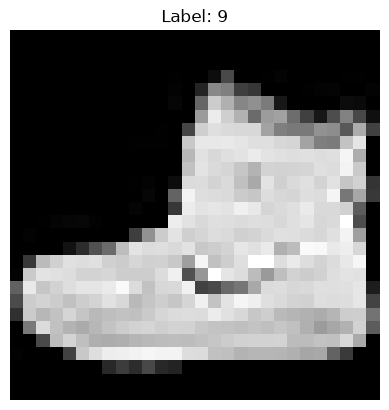

In [3]:
import matplotlib.pyplot as plt

plt.imshow(X_train[0], cmap='gray')
plt.title(f'Label: {y_train[0]}')
plt.axis('off')
plt.show()

In [10]:
import numpy as np

daftar_kelas = np.unique(y_train)
print("Daftar kelas:", daftar_kelas)
print("Jumlah kelas:", len(daftar_kelas))

Daftar kelas: [0 1 2 3 4 5 6 7 8 9]
Jumlah kelas: 10


preprocessing data

In [ ]:
#cek pixel
print('max pixel train:',X_train.max())
print('max pixel train:',X_test.max())

max pixel train: 255
max pixel train: 255


In [14]:
#Normaliassi pixel
X_train = X_train/ 255.0
X_test = X_test/255.0

#Tambahkan channel
X_train = X_train.reshape(-1,28,28,1)
X_test =X_test.reshape(-1,28,28,1)

print("Setelah preprocessing:")
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)

Setelah preprocessing:
X_train : (60000, 28, 28, 1)
X_test  : (10000, 28, 28, 1)


Model CNN

In [16]:
model = Sequential([Conv2D(32,(3,3),activation='relu', input_shape=(28,28,1)),
                    MaxPooling2D((2,2)),
                    Conv2D(64, (3,3), activation='relu'),
                    MaxPooling2D((3,3)),
                    Flatten(),
                    Dense(128, activation='relu'),
                    Dense(10,activation='softmax')])
model.summary()

c:\Users\MyBook Hype\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,962 (367.04 KB)

 Trainable params: 93,962 (367.04 KB)

 Non-trainable params: 0 (0.00 B)

Compile Model

In [17]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

Train Model

In [19]:
history = model.fit(X_train, y_train, epochs=10, batch_size=128,validation_split=0.2)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 78ms/step - accuracy: 0.8904 - loss: 0.2959 - val_accuracy: 0.8767 - val_loss: 0.3316
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 29s 78ms/step - accuracy: 0.8977 - loss: 0.2769 - val_accuracy: 0.8853 - val_loss: 0.3140
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 76ms/step - accuracy: 0.9030 - loss: 0.2651 - val_accuracy: 0.8886 - val_loss: 0.3070
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 37s 64ms/step - accuracy: 0.9068 - loss: 0.2533 - val_accuracy: 0.8878 - val_loss: 0.3069
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 26s 68ms/step - accuracy: 0.9119 - loss: 0.2390 - val_accuracy: 0.8945 - val_loss: 0.2898
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 17s 46ms/step - accuracy: 0.9157 - loss: 0.2290 - val_accuracy: 0.8925 - val_loss: 0.2983
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 20s 45ms/step - accuracy: 0.9187 - loss: 0.2197 - val_accuracy: 0.9003 - val_loss: 0.2818
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 17s 45ms/step - accuracy: 0.9216 - loss: 0.2126 - 

Evaluasi

In [20]:
# Accuracy Train
train_loss, train_accuracy = model.evaluate(X_train, y_train)
print('Train loss :',train_loss)
print('Train Accuracy : ', train_accuracy)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9285 - loss: 0.1992
Train loss : 0.19920267164707184
Train Accuracy :  0.928516685962677


In [21]:
# Accuracy Test
test_loss, test_accuracy =model.evaluate(X_test, y_test)
print('Test loss :',test_loss)
print('Test accuracy :', test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8948 - loss: 0.2959
Test loss : 0.2959388196468353
Test accuracy : 0.8948000073432922


Prediksi (Test Model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
Label sebenarnya : 4
Label Prediksi : 4


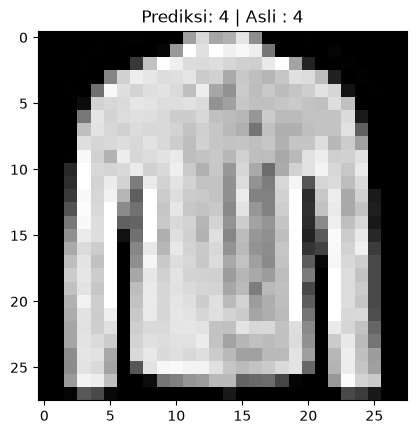

In [27]:
index = 50

gambar = X_test[index]
prediksi = model.predict(np.expand_dims(gambar, axis=0))
hasil = np.argmax(prediksi)
print('Label sebenarnya :',y_test[index])
print('Label Prediksi :', hasil)
plt.imshow(gambar.squeeze(), cmap='gray')
plt.title(f'Prediksi: {hasil} | Asli : {y_test[index]}')
plt.axis()
plt.show()